**Nama:** Indah Faizah Salsabillah Ramdhany Wadjo
**NIM:** 24031554210 
**Program Studi:** S1 Sains Data  

# 1.2

In [ ]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Salsabillah09")

driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")
finally:
    driver.close()

Koneksi ke Neo4j berhasil!


C:\Users\Asus\AppData\Local\Temp\ipykernel_20164\2407828438.py:12: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [23]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (friend:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(friend)
            """,
            name=name,
            friend_name=friend_name
        )


def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend)
            WHERE a.name = $name
            RETURN friend.name AS friend
            ORDER BY friend
            """,
            name=name
        )

        for record in result:
            print(record["friend"])


driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print_friends(driver, "Arthur")
finally:
    driver.close()

C:\Users\Asus\AppData\Local\Temp\ipykernel_20164\4118654408.py:33: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Guinevere
Lancelot
Merlin


### Pertanyaan Pendahuluan (Checkpint)

***1. Apa nama database yang digunakan pada tutorial ini?***

Answer: Database yang digunakan pada tutorial ini adalah neo4j, sesuai dengan nama database yang ditentukan pada konfigurasi koneksi Python Driver Neo4j.

***2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan mengakses database lain dalam satu instance!***

Answer: Selain menggunakan cypher, database lain dalam satu instance Neo4j dapat diakses menggunakan perintah DDL untuk mengatur struktur database, seperti CREATE INDEX dan CREATE CONSTRAINT, serta DML untuk memanipulasi data, seperti CREATE, MERGE, SET, dan DELETE.


***3. Apa jenis graf pertemanan yang telah dibuat di sini?***

Answer: Graf pertemanan yang dibuat merupakan directed graph karena relasi KNOWS memiliki arah dari simpul Arthur menuju simpul temannya. Graf ini juga tidak berbobot karena relasi tidak memiliki nilai bobot. Relasi tersebut menghubungkan simpul person yang mewakili orang.

# 1.3 Impor data RetailRocket ke Neo4j

In [24]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


### 1.3.1 Mengunduh dan memahami dataset

In [25]:
import pandas as pd
import os

file_path = os.path.join("data", "events.csv")
df = pd.read_csv(file_path)
display(df.head())

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [26]:
print("Nama kolom:")
print(df.columns.tolist())

print("\nUkuran dataset:")
print(df.shape)

print("\nLima baris pertama:")
display(df.head())

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Ukuran dataset:
(2756101, 5)

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [27]:
print("Ukuran dataset:", df.shape)

print("\nJumlah setiap jenis event:")
display(df["event"].value_counts())

print("\nJumlah missing values:")
display(df.isnull().sum())

Ukuran dataset: (2756101, 5)

Jumlah setiap jenis event:


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


Jumlah missing values:


timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

### 1.3.2 Tes koneksi dan database tujuan

In [28]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"

driver = GraphDatabase.driver(URI, auth=AUTH)

with driver.session(database="neo4j") as session:
    result = session.run("RETURN 'Koneksi berhasil' AS status")
    print(result.single()["status"])

driver.close()

Koneksi berhasil


### 1.3.3 Pemeriksaan versi Python dan library

In [29]:
import sys
import pandas as pd
import neo4j

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("Neo4j:", neo4j.__version__)

Python: d:\KULIAH\myenv\Scripts\python.exe
Pandas: 2.3.3
Neo4j: 4.2.1


### 1.3.4 Memeriksa file dataset

In [30]:
from pathlib import Path
import pandas as pd

data_path = Path("data/events.csv")

print("File ditemukan:", data_path.exists())

if data_path.exists():
    print("Ukuran file:", round(data_path.stat().st_size / (1024**2), 2), "MB")
    df = pd.read_csv(data_path, nrows=5)
    display(df)

File ditemukan: True
Ukuran file: 89.87 MB


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [31]:
import pandas as pd
from datetime import datetime, timezone

data_path = "data/events.csv"

events_time = pd.read_csv(data_path, usecols=["timestamp"])

events_time["datetime"] = pd.to_datetime(
    events_time["timestamp"],
    unit="ms",
    utc=True
)

print("Tanggal paling awal:", events_time["datetime"].min())
print("Tanggal paling akhir:", events_time["datetime"].max())

Tanggal paling awal: 2015-05-03 03:00:04.384000+00:00
Tanggal paling akhir: 2015-09-18 02:59:47.788000+00:00


# 2.1 Wrangling dan EDA

### 2.1.1 Memfilter Data P1 dan P2

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. 
P1 = 3 Mei - 14 Mei 2015 
P2 = 15 Mei - 26 Mei 2015


In [32]:
import pandas as pd

data_path = "data/events.csv"

events = pd.read_csv(data_path)

events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

p1_start = pd.Timestamp("2015-05-03 00:00:00", tz="UTC")
p1_end   = pd.Timestamp("2015-05-15 00:00:00", tz="UTC")

p2_start = pd.Timestamp("2015-05-15 00:00:00", tz="UTC")
p2_end   = pd.Timestamp("2015-05-27 00:00:00", tz="UTC")

training = events[
    (events["datetime"] >= p1_start) &
    (events["datetime"] < p1_end)
].copy()

testing = events[
    (events["datetime"] >= p2_start) &
    (events["datetime"] < p2_end)
].copy()

print("Jumlah data training:", len(training))
print("Jumlah data testing:", len(testing))

print("\nJenis interaksi training:")
print(training["event"].value_counts())

print("\nJenis interaksi testing:")
print(testing["event"].value_counts())

Jumlah data training: 233933
Jumlah data testing: 260760

Jenis interaksi training:
event
view           226005
addtocart        6008
transaction      1920
Name: count, dtype: int64

Jenis interaksi testing:
event
view           252842
addtocart        6001
transaction      1917
Name: count, dtype: int64


### 2.1.2 Menyimpan data filter ke csv

2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [33]:
from pathlib import Path

output_dir = Path("data/hasil_wrangling")
output_dir.mkdir(parents=True, exist_ok=True)

training.to_csv(output_dir / "training_P1.csv", index=False)
testing.to_csv(output_dir / "testing_P2.csv", index=False)

print("Jumlah data P1:", len(training))
print("Jumlah data P2:", len(testing))
print("Data hasil wrangling tersimpan di:", output_dir.resolve())

Jumlah data P1: 233933
Jumlah data P2: 260760
Data hasil wrangling tersimpan di: D:\KULIAH\UTS GRAF\data\hasil_wrangling


### 2.1.3 Analisis Komposisi Subgraph Menggunakan Neo4j serta jenis simpul dan jumlah masing-masing simpul

3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

2.1.3. Menghitung subgraph dan jenis simpul serta jumlah masing-masing simpul

In [ ]:

import pandas as pd

with driver.session(database="neo4j") as session:

    query_nodes = """
    MATCH (n)
    WHERE n:Visitor OR n:Item
    UNWIND labels(n) AS jenis_simpul
    RETURN jenis_simpul, count(*) AS jumlah
    ORDER BY jenis_simpul
    """

    nodes_result = session.run(query_nodes)
    nodes_df = pd.DataFrame(
        [record.data() for record in nodes_result]
    )

    query_relationships = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
      AND r.period IN ['P1', 'P2']
    RETURN
        type(r) AS jenis_relasi,
        r.period AS periode,
        count(*) AS jumlah
    ORDER BY periode, jenis_relasi
    """

    relationships_result = session.run(query_relationships)
    relationships_df = pd.DataFrame(
        [record.data() for record in relationships_result]
    )

print("KOMPOSISI SIMPUL RETAILROCKET")
display(nodes_df)

print("KOMPOSISI RELASI RETAILROCKET")
display(relationships_df)


KOMPOSISI SIMPUL RETAILROCKET


,jenis_simpul,jumlah
0,Item,104681
1,Visitor,257736


KOMPOSISI RELASI RETAILROCKET


,jenis_relasi,periode,jumlah
0,ADDED_TO_CART,P1,5984
1,BOUGHT,P1,1920
2,VIEWED,P1,226000
3,ADDED_TO_CART,P2,5983
4,BOUGHT,P2,1917
5,VIEWED,P2,252834


Answer: Komposisi simpul pada subgraph RetailRocket dianalisis menggunakan python API Neo4j dengan menjalankan query cypher. Berdasarkan label yang digunakan dalam graf, terdapat simpul visitor yang merepresentasikan pengguna dan simpul item yang merepresentasikan barang. Jumlah masing-masing jenis simpul ini diperoleh melalui hasil query dan ditampilkan dalam tabel. Query cypher menggunakan MATCH (n) untuk mengambil simpul, labels(n) untuk memperoleh label simpul, serta count(*) untuk menghitung jumlah simpul berdasarkan jenisnya. Hasilnya kemudian diurutkan menggunakan ORDER BY lalu ditampilkan melalui python API. Informasi ini digunakan untuk memahami komposisi graf sebelum dilakukan pembentukan VSM.

### 2.1.4 Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [35]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [36]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        WHERE r.period = 'P1'
          AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
        RETURN DISTINCT
            v.visitorId AS visitor_id,
            i.itemId AS item_id
    """)

    interactions_p1 = pd.DataFrame(
        [record.data() for record in result]
    )

user_ids = interactions_p1["visitor_id"].drop_duplicates().tolist()
item_ids = interactions_p1["item_id"].drop_duplicates().tolist()

user_to_idx = {v: i for i, v in enumerate(user_ids)}
item_to_idx = {v: i for i, v in enumerate(item_ids)}

rows = interactions_p1["visitor_id"].map(user_to_idx).to_numpy()
cols = interactions_p1["item_id"].map(item_to_idx).to_numpy()

user_item_matrix = csr_matrix(
    (
        np.ones(len(interactions_p1), dtype=np.int8),
        (rows, cols)
    ),
    shape=(len(user_ids), len(item_ids))
)

density = (
    user_item_matrix.nnz /
    (user_item_matrix.shape[0] * user_item_matrix.shape[1])
) * 100

print("Jumlah User:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Dimensi VSM:", user_item_matrix.shape)
print("Jumlah elemen nonnol:", user_item_matrix.nnz)
print("Kepadatan matriks:", round(density, 6), "%")

Jumlah User: 123812
Jumlah Item: 67985
Dimensi VSM: (123812, 67985)
Jumlah elemen nonnol: 183127
Kepadatan matriks: 0.002176 %


In [37]:
%pip install networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


Jumlah simpul: 100
Jumlah sisi: 755
Kepadatan graf: 0.152525


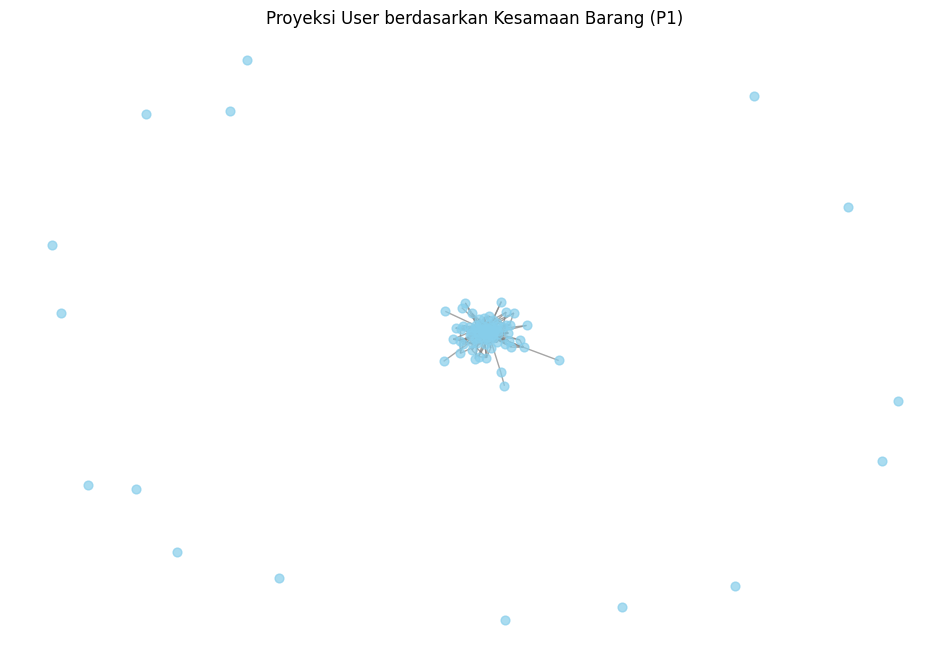

In [38]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

user_activity = np.asarray(user_item_matrix.sum(axis=1)).ravel()
top_n = min(100, len(user_ids))
top_idx = np.argsort(user_activity)[-top_n:]

sample_matrix = user_item_matrix[top_idx]

shared_items = sample_matrix @ sample_matrix.T

G_user = nx.Graph()

for idx in top_idx:
    G_user.add_node(user_ids[idx])

coo = shared_items.tocoo()

for i, j, weight in zip(coo.row, coo.col, coo.data):
    if i < j and weight >= 2:
        G_user.add_edge(
            user_ids[top_idx[i]],
            user_ids[top_idx[j]],
            weight=int(weight)
        )

print("Jumlah simpul:", G_user.number_of_nodes())
print("Jumlah sisi:", G_user.number_of_edges())
print("Kepadatan graf:", round(nx.density(G_user), 6))

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    with_labels=False,
    node_size=40,
    node_color="skyblue",
    edge_color="gray",
    alpha=0.7
)

plt.title("Proyeksi User berdasarkan Kesamaan Barang (P1)")
plt.axis("off")
plt.show()

Answer: VSM dilakukan dengan merepresentasikan setiap user sebagai vektor berdasarkan interaksinya dengan item pada periode P1. Hasilnya menunjukkan terdapat 123.812 user dan 67.985 item, dengan shape matriks sebesar 123812, 67985 dan dimensi 2. Matriks memiliki 183.127 elemen nonnol dengan kepadatan 0,002176%, yang menunjukkan bahwa matriks bersifat sangat sparse karena sebagian besar user hanya berinteraksi dengan sebagian kecil item. Pada visualisasi proyeksi menggunakan NetworkX, kumpulan simpul yang rapat menunjukkan user yang memiliki kesamaan item dan saling terhubung, sedangkan simpul yang terpisah menunjukkan user yang tidak terhubung berdasarkan kriteria kesamaan yang digunakan. Dengan demikian, VSM dapat digunakan sebagai dasar untuk menganalisis kemiripan antaruser dan membangun sistem rekomendasi.

### 2.1.5 Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (di- mensi, shape, plot networkx, dst.)!

In [39]:
item_user_matrix = user_item_matrix.T.tocsr()

item_activity = np.asarray(
    item_user_matrix.sum(axis=1)
).ravel()

density_item = (
    item_user_matrix.nnz /
    (item_user_matrix.shape[0] * item_user_matrix.shape[1])
) * 100

print("Jumlah Item:", item_user_matrix.shape[0])
print("Jumlah User:", item_user_matrix.shape[1])
print("Dimensi VSM Item:", item_user_matrix.shape)
print("Jumlah elemen nonnol:", item_user_matrix.nnz)
print("Kepadatan matriks:", round(density_item, 6), "%")

Jumlah Item: 67985
Jumlah User: 123812
Dimensi VSM Item: (67985, 123812)
Jumlah elemen nonnol: 183127
Kepadatan matriks: 0.002176 %


Jumlah simpul: 100
Jumlah sisi: 420
Kepadatan graf: 0.084848


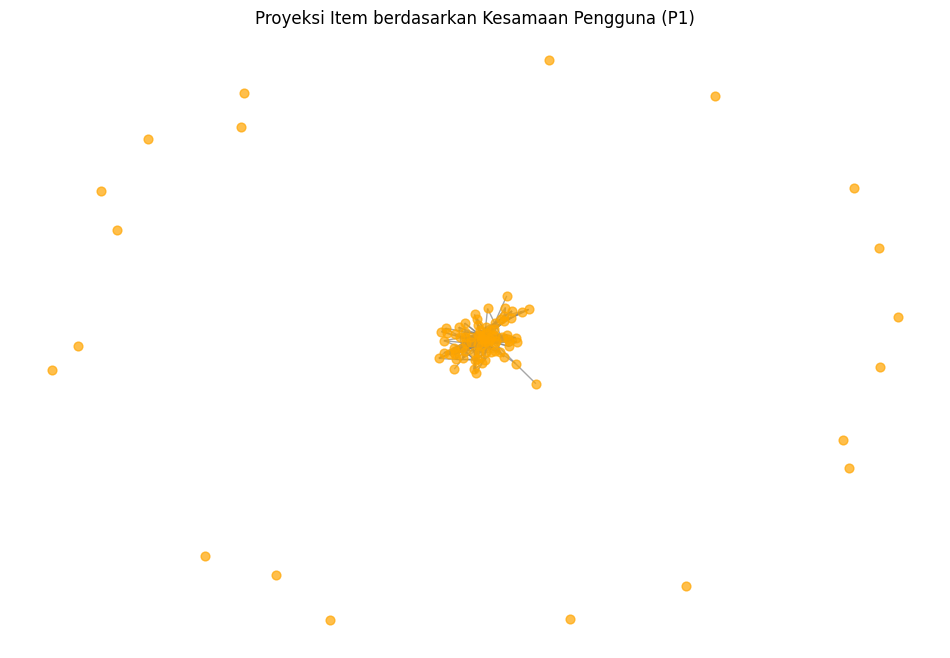

In [40]:
top_n_item = min(100, len(item_ids))
top_item_idx = np.argsort(item_activity)[-top_n_item:]

sample_item_matrix = item_user_matrix[top_item_idx]

shared_users = sample_item_matrix @ sample_item_matrix.T

G_item = nx.Graph()

for idx in top_item_idx:
    G_item.add_node(item_ids[idx])

coo = shared_users.tocoo()

for i, j, weight in zip(coo.row, coo.col, coo.data):
    if i < j and weight >= 2:
        G_item.add_edge(
            item_ids[top_item_idx[i]],
            item_ids[top_item_idx[j]],
            weight=int(weight)
        )

print("Jumlah simpul:", G_item.number_of_nodes())
print("Jumlah sisi:", G_item.number_of_edges())
print("Kepadatan graf:", round(nx.density(G_item), 6))

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos,
    with_labels=False,
    node_size=40,
    node_color="orange",
    edge_color="gray",
    alpha=0.7
)

plt.title("Proyeksi Item berdasarkan Kesamaan Pengguna (P1)")
plt.axis("off")
plt.show()

VSM item pada periode P1 memiliki dimensi (shape) sebesar (67.985, 123.812), dengan 183.127 elemen nonnol dan kepadatan matriks sebesar 0,002176%. Hal ini menunjukkan bahwa matriks sangat sparse, karena hanya sebagian kecil pasangan barang dan pengguna yang memiliki interaksi. Visualisasi NetworkX menggunakan 100 barang dengan interaksi terbanyak. Setiap simpul merepresentasikan barang, sedangkan sisi menunjukkan dua barang yang memiliki minimal dua pengguna yang sama. Proyeksi ini digunakan untuk mengidentifikasi barang-barang dengan pola interaksi pengguna yang serupa.

### 2.1.6 Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Answer:

Berdasarkan eksplorasi nomor 4 dan 5, kedua proyeksi memiliki efektivitas yang berbeda sesuai tujuan analisis. Proyeksi User lebih efektif untuk menemukan pengguna dengan pola interaksi barang yang serupa, sedangkan proyeksi Item lebih efektif untuk menemukan barang yang memiliki kesamaan pengguna. Dari segi efisiensi, keduanya menggunakan matriks VSM yang sangat *sparse*, sehingga representasi matriks dalam format sparse dapat menghemat penggunaan memori. Oleh karena itu, proyeksi yang lebih baik bergantung pada tujuan analisis. Untuk rekomendasi barang, proyeksi Item lebih relevan, sedangkan untuk pengelompokan pengguna, proyeksi User lebih sesuai.

### 2.1.7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

In [41]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [42]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(sample_item_matrix)

anchor_idx = int(np.argmax(
    np.asarray(sample_item_matrix.sum(axis=1)).ravel()
))

anchor_item_id = item_ids[top_item_idx[anchor_idx]]

similarities = similarity_matrix[anchor_idx]

similarity_df = pd.DataFrame({
    "item_id": [item_ids[i] for i in top_item_idx],
    "similarity": similarities
})

top_similar_items = (
    similarity_df[
        similarity_df["item_id"] != anchor_item_id
    ]
    .sort_values("similarity", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

print("Anchor Item:", anchor_item_id)
print("\nLima item paling mirip:")
display(top_similar_items)

Anchor Item: 369447

Lima item paling mirip:


,item_id,similarity
0,69533,0.081937
1,37029,0.060552
2,133907,0.057549
3,312717,0.043725
4,51354,0.039124


(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi

answer: 

In [43]:
similarity_records = [
    {
        "item_id": int(row.item_id),
        "similarity": float(row.similarity)
    }
    for row in top_similar_items.itertuples(index=False)
]

anchor_item_id = int(anchor_item_id)

def save_similarity(tx, anchor_id, records):
    query = """
    MATCH (a:Item {itemId: $anchor_id})
    UNWIND $records AS row
    MATCH (b:Item {itemId: row.item_id})
    MERGE (a)-[r:SIMILAR_TO {period: 'P1'}]->(b)
    SET r.similarity = row.similarity,
        r.method = 'cosine'
    RETURN count(r) AS jumlah_relasi
    """
    result = tx.run(query, anchor_id=anchor_id, records=records)
    return result.single()["jumlah_relasi"]

with driver.session(database="neo4j") as session:
    jumlah_relasi = session.write_transaction(
        save_similarity, anchor_item_id, similarity_records
    )

print("Jumlah relasi yang tersimpan:", jumlah_relasi)

Jumlah relasi yang tersimpan: 5


In [57]:
query_similarity = """
MATCH (a:Item {itemId: $anchor_id})-[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN a.itemId AS anchor_item,
       b.itemId AS similar_item,
       r.similarity AS similarity
ORDER BY r.similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        query_similarity,
        anchor_id=anchor_item_id
    )
    similarity_result = pd.DataFrame(
        [record.data() for record in result]
    )

display(similarity_result)

,anchor_item,similar_item,similarity
0,369447,69533,0.081937
1,369447,37029,0.060552
2,369447,133907,0.057549
3,369447,312717,0.043725
4,369447,51354,0.039124


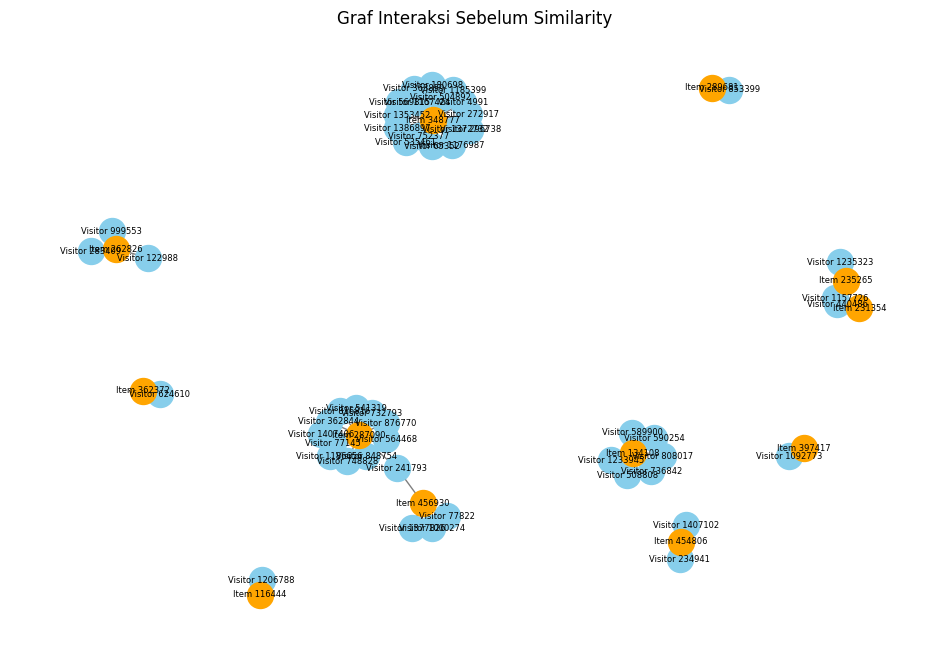

In [45]:
import networkx as nx
import matplotlib.pyplot as plt

G_before = nx.Graph()

sample_before = interactions_p1.head(50)

for row in sample_before.itertuples(index=False):
    visitor = f"Visitor {row.visitor_id}"
    item = f"Item {row.item_id}"

    G_before.add_node(visitor, node_type="Visitor")
    G_before.add_node(item, node_type="Item")
    G_before.add_edge(visitor, item)

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_before, seed=42)

visitor_nodes = [
    n for n, d in G_before.nodes(data=True)
    if d["node_type"] == "Visitor"
]
item_nodes = [
    n for n, d in G_before.nodes(data=True)
    if d["node_type"] == "Item"
]

nx.draw_networkx_nodes(
    G_before, pos, nodelist=visitor_nodes,
    node_color="skyblue", node_size=350
)
nx.draw_networkx_nodes(
    G_before, pos, nodelist=item_nodes,
    node_color="orange", node_size=350
)
nx.draw_networkx_edges(G_before, pos, alpha=0.5)
nx.draw_networkx_labels(G_before, pos, font_size=6)

plt.title("Graf Interaksi Sebelum Similarity")
plt.axis("off")
plt.show()

(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-
nya!

In [46]:
query_similarity = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN a.itemId AS anchor_item,
       b.itemId AS similar_item,
       r.similarity AS similarity,
       r.method AS method,
       r.period AS period
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_similarity)
    similarity_result = pd.DataFrame(
        [record.data() for record in result]
    )

display(similarity_result)

,anchor_item,similar_item,similarity,method,period
0,369447,69533,0.081937,cosine,P1
1,369447,37029,0.060552,cosine,P1
2,369447,133907,0.057549,cosine,P1
3,369447,312717,0.043725,cosine,P1
4,369447,51354,0.039124,cosine,P1


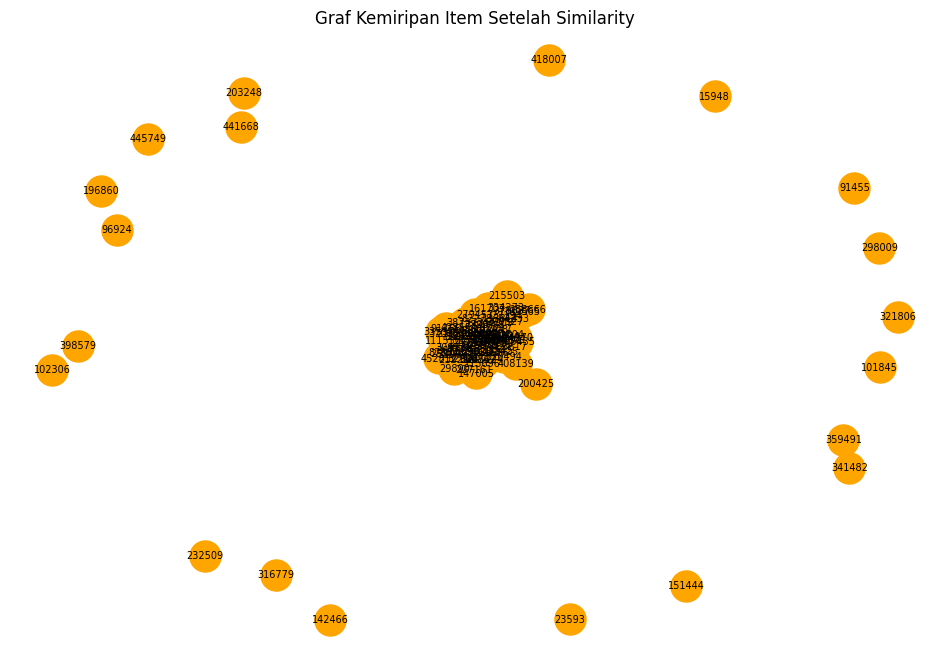

In [47]:
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx_nodes(
    G_item, pos,
    node_color="orange",
    node_size=500
)
nx.draw_networkx_edges(
    G_item, pos,
    width=[
        G_item[u][v]["weight"] / 2
        for u, v in G_item.edges()
    ],
    alpha=0.5
)
nx.draw_networkx_labels(G_item, pos, font_size=7)

plt.title("Graf Kemiripan Item Setelah Similarity")
plt.axis("off")
plt.show()

2.1.8 Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!

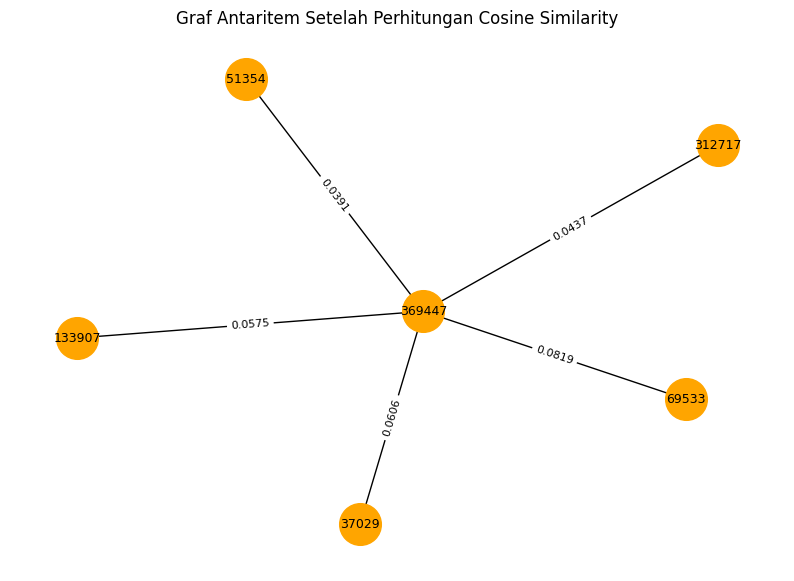

In [58]:
plt.figure(figsize=(10, 7))

pos = nx.spring_layout(G_after, seed=42)

nx.draw_networkx(
    G_after,
    pos,
    with_labels=True,
    node_color="orange",
    node_size=900,
    font_size=9
)

edge_labels = {
    (u, v): f"{data['weight']:.4f}"
    for u, v, data in G_after.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G_after,
    pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title("Graf Antaritem Setelah Perhitungan Cosine Similarity")
plt.axis("off")
plt.show()

Perbandingan kedua graf menunjukkan bahwa sebelum perhitungan similarity, graf merepresentasikan aktivitas interaksi pengunjung terhadap item. Setelah perhitungan similarity, graf memiliki relasi tambahan SIMILAR_TO yang menghubungkan item-item berdasarkan kemiripan pola interaksi pengguna. Dengan demikian, graf tidak hanya menyimpan informasi aktivitas, tetapi juga dapat digunakan untuk mengidentifikasi item yang memiliki kemiripan.

# 2.2 Analytics

2.2.1 Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

Mengambil data interaksi P2

In [49]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        WHERE r.period = 'P2'
          AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
        RETURN DISTINCT
            v.visitorId AS visitor_id,
            i.itemId AS item_id
    """)

    interactions_p2 = pd.DataFrame(
        [record.data() for record in result]
    )

print("Jumlah interaksi P2:", len(interactions_p2))

Jumlah interaksi P2: 205347


Memilih user secara acak

In [50]:
import numpy as np
import pandas as pd

users_p1 = set(interactions_p1["visitor_id"])
users_p2 = set(interactions_p2["visitor_id"])

eligible_users = sorted(users_p1 & users_p2)

rng = np.random.default_rng(42)
selected_user = rng.choice(eligible_users).item()

print("Random state:", 42)
print("User terpilih:", selected_user)
print("Jumlah kandidat user:", len(eligible_users))

Random state: 42
User terpilih: 116768
Jumlah kandidat user: 6396


Membentuk matriks user-item

In [51]:
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

train = interactions_p1.drop_duplicates(
    ["visitor_id", "item_id"]
).copy()

user_ids = sorted(train["visitor_id"].unique())
item_ids = sorted(train["item_id"].unique())

user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

rows = train["visitor_id"].map(user_to_idx).to_numpy()
cols = train["item_id"].map(item_to_idx).to_numpy()

user_item_matrix = csr_matrix(
    (
        np.ones(len(train), dtype=np.float32),
        (rows, cols)
    ),
    shape=(len(user_ids), len(item_ids))
)

print("Ukuran matriks:", user_item_matrix.shape)

Ukuran matriks: (123812, 67985)


Menentukan lima tetangga terdekat

In [59]:
target_idx = user_to_idx[selected_user]

knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

knn.fit(user_item_matrix)

distances, indices = knn.kneighbors(
    user_item_matrix[target_idx],
    n_neighbors=6
)

candidate_indices = indices[0]
candidate_distances = distances[0]

neighbors = [
    (idx, dist)
    for idx, dist in zip(candidate_indices, candidate_distances)
    if idx != target_idx and (1 - dist) > 0
]

neighbors = sorted(
    neighbors,
    key=lambda x: x[1]
)[:5]

neighbor_indices = [idx for idx, dist in neighbors]
neighbor_distances = [dist for idx, dist in neighbors]

neighbors_df = pd.DataFrame({
    "neighbor_id": [user_ids[i] for i in neighbor_indices],
    "cosine_distance": neighbor_distances,
    "similarity": [1 - d for d in neighbor_distances]
})

print("Jumlah tetangga dengan similarity positif:", len(neighbors_df))
display(neighbors_df)

Jumlah tetangga dengan similarity positif: 1


,neighbor_id,cosine_distance,similarity
0,291720,0.591752,0.408248


Menghasilkan lima rekomendasi

In [60]:
neighbor_matrix = user_item_matrix[neighbor_indices]
item_scores = np.asarray(neighbor_matrix.sum(axis=0)).ravel()

seen_items = set(
    train.loc[
        train["visitor_id"] == selected_user,
        "item_id"
    ]
)

recommendation_df = pd.DataFrame({
    "item_id": item_ids,
    "score": item_scores
})

recommendation_df = recommendation_df[
    (recommendation_df["score"] > 0)
    & (~recommendation_df["item_id"].isin(seen_items))
]

recommendation_df = (
    recommendation_df
    .sort_values(
        ["score", "item_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

top5_recommendations = recommendation_df.head(5).copy()

print("User terpilih:", selected_user)
display(top5_recommendations)

User terpilih: 116768


,item_id,score
0,65580,1.0
1,140491,1.0
2,221822,1.0
3,269969,1.0
4,294965,1.0


(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

Menampilkan tiga item

In [61]:
top3_recommendations = top5_recommendations.head(3)

display(top3_recommendations)

,item_id,score
0,65580,1.0
1,140491,1.0
2,221822,1.0


### 2.2.2 Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

(a) Hit@5

In [62]:
relevant_items = set(
    interactions_p2.loc[
        interactions_p2["visitor_id"] == selected_user,
        "item_id"
    ]
)

recommended_items = top5_recommendations["item_id"].tolist()

hits = [
    1 if item in relevant_items else 0
    for item in recommended_items
]

hit_at_5 = int(sum(hits) > 0)

print("User:", selected_user)
print("Lima item rekomendasi:", recommended_items)
print("Item relevan pada P2:", len(relevant_items))
print("Jumlah rekomendasi yang relevan:", sum(hits))
print("Hit@5:", hit_at_5)

User: 116768
Lima item rekomendasi: [65580, 140491, 221822, 269969, 294965]
Item relevan pada P2: 1
Jumlah rekomendasi yang relevan: 0
Hit@5: 0


(b) NDCG@5

In [63]:
hits_array = np.array(hits, dtype=float)

discounts = np.log2(np.arange(2, len(hits_array) + 2))
dcg_at_5 = np.sum(hits_array / discounts)

ideal_length = min(len(relevant_items), 5)
ideal_hits = np.ones(ideal_length)

ideal_discounts = np.log2(
    np.arange(2, ideal_length + 2)
)

idcg_at_5 = np.sum(ideal_hits / ideal_discounts)

ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

print("DCG@5:", round(float(dcg_at_5), 4))
print("IDCG@5:", round(float(idcg_at_5), 4))
print("NDCG@5:", round(float(ndcg_at_5), 4))

DCG@5: 0.0
IDCG@5: 1.0
NDCG@5: 0.0


Berdasarkan hasil evaluasi sistem rekomendasi KNN, diperoleh nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0. Hal ini menunjukkan bahwa tidak terdapat item yang direkomendasikan pada lima peringkat teratas yang sesuai dengan interaksi pengguna pada periode pengujian (P2). Dengan demikian, sistem rekomendasi belum berhasil menghasilkan rekomendasi yang relevan bagi pengguna terpilih pada periode tersebut. Nilai ini hanya menggambarkan hasil evaluasi untuk satu pengguna terpilih, sehingga belum dapat digunakan untuk menyimpulkan kinerja sistem rekomendasi secara keseluruhan.